# 실험 2 — 3. 딥러닝: 논문 구조(Conv1D–BiLSTM–Attention + 표 형식 가지) 재현과 하이퍼파라미터 탐색

`docs/참고자료/0808Manuscript.2.docx`(아플라톡신 부적합 예측, Table 2)의 두 가지(branch) 신경망을 PyTorch 로 옮겨 리스테리아 데이터에 맞춘다. 결과는 MLflow 실험 `리스테리아_EXP2` 에 기록한다.

| 가지 | 논문 | 이 노트북 |
|---|---|---|
| 시계열 | 기상 10변수 × 50일 → Conv1D(64, k=7) → Conv1D(64, k=3) → BiLSTM(64) → BiLSTM(32) → Bahdanau attention | 기상·대기 **17변수 × 100일**(`data/exp2/seq_std.npy`, train 통계로 표준화) → 같은 구조. 창 길이·필터 수·커널은 탐색 대상 |
| 표 형식 | 검사목적·식품군(원핫) + 파생 지표 3 → Dense(64) → Dense(32) | 범주형 8개(LIMS 5 + 식품 값 표기 3 — 2026-10-01: 검사기관 코드 제거)는 **임베딩**(원핫 대신 — `prdlst_code` 819종을 원핫하면 너무 넓음) + 수치 359개(식품 3 + 기상 창 집계 353 + 식품 결측 표시 3, train 통계로 표준화) → Dense(64) → Dense(32) |
| 결합·출력 | concat → Dense → sigmoid | concat → Dense → 로짓 1개(`BCEWithLogitsLoss`, sigmoid 는 손실 안에서) |
| 정규화 | BatchNorm, Dropout 0.1, L2 1e-3 | 같음. **층 순서는 Dense/Conv → BatchNorm → 활성화 → Dropout 으로 고정**(논문 본문은 순서를 명시하지 않았고, 이 순서가 표준·안전) |
| 손실·학습 | 가중 BCE(양성 가중 = 음성/양성 수), Adam lr 1e-4, batch 256, 최대 50 epoch, 조기 종료 patience 10(val PR-AUC), clipnorm 1.0 | 같음 |
| 불균형 | 양성 3배 오버샘플링(증강 사본 2개: 변수별 배율 0.95~1.05, 잡음 σ 0.02, 시간 이동 ±2일 가장자리 복제) | 같음 (학습 배치에서 즉석 증강). 탐색에서 끄는 선택지도 둔다 |

**두 모델을 기록한다**
1. `DL_논문설정` — 논문 값 그대로(탐색 없음, 논문의 "고정 설정" 대조군에 해당).
2. `DL_튜닝` — Optuna(TPE) 로 학습률·dropout·L2·양성 가중·Conv 층 수·필터·커널·LSTM 크기·Dense 크기·배치·증강 여부·창 길이를 탐색한 뒤 val PR-AUC 최고 시도(최대 `N_TRIALS` 회 또는 `DL_BUDGET_H` 시간).

공통 규칙(분할·val 의 쓰임·임계값 규칙·지표)은 `2_autogluon.ipynb` 와 같다. GPU: RTX 2060. cuDNN LSTM 은 같은 seed 로 다시 돌려도 결과가 아주 조금 달라질 수 있다.

> **`SMOKE_TEST = True`** 면 작은 표본·1~2 epoch 으로 파이프라인만 점검하고 MLflow 에 기록하지 않는다.

## 1. 설정

In [1]:
import gc
import json
import logging
import math
import os
import sys
import tempfile
import time
import warnings
from datetime import datetime
warnings.filterwarnings('ignore', message='IProgress not found')
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import torch
import torch.nn as nn
import optuna
os.environ.setdefault('MLFLOW_DISABLE_AGENT_HINT', '1')
import mlflow
from dotenv import dotenv_values
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
                             roc_auc_score, average_precision_score, confusion_matrix, precision_recall_curve)

SMOKE_TEST = False
LOG_TO_MLFLOW = True
SEED = 42
RUN_NAME = '3_딥러닝'
RUN_STAMP = datetime.now().strftime('%Y%m%d_%H%M')

# 논문 설정 (Table 2)
PAPER = dict(seq_len=100, conv_filters=64, kernel1=7, n_conv=2, lstm1=64, lstm2=32, dense_tab=(64, 32), dense_fuse=64,
             dropout=0.1, l2=1e-3, lr=1e-4, batch_size=256, pos_weight_mode='full', augment=True)
MAX_EPOCHS, PATIENCE = 50, 10               # 논문: 최대 50 epoch, patience 10 (val PR-AUC)
# 탐색
N_TRIALS = 25                               # 최대 시도 수
DL_BUDGET_H = 6                             # 탐색 시간 예산(시간) — 먼저 닿는 쪽에서 멈춤
HPO_MAX_EPOCHS, HPO_PATIENCE = 40, 8        # 탐색 시도의 최대 epoch·patience + Optuna 가지치기
if SMOKE_TEST:
    MAX_EPOCHS, PATIENCE, N_TRIALS, HPO_MAX_EPOCHS, HPO_PATIENCE, DL_BUDGET_H = 2, 1, 2, 2, 1, 0.1
    LOG_TO_MLFLOW = False

PROJECT_DIR = Path(r'C:\Users\NT751\Desktop\천영진\리스테리아ML')
DATA_DIR = PROJECT_DIR / 'data' / 'exp2'
OUT_DIR = PROJECT_DIR / 'output' / 'exp2' / 'dl' / ('smoke_' if SMOKE_TEST else '') / RUN_STAMP   # 체크포인트 (git 제외)
OUT_DIR.mkdir(parents=True, exist_ok=True)
OPTUNA_DIR = PROJECT_DIR / (dotenv_values(PROJECT_DIR / '.env').get('AFLA_OPTUNA_DIR') or 'output')
OPTUNA_DIR.mkdir(parents=True, exist_ok=True)
OPTUNA_STORAGE = 'sqlite:///' + (OPTUNA_DIR / ('optuna_exp2_dl_smoke.db' if SMOKE_TEST else 'optuna_exp2_dl.db')).as_posix()
KEY_COL, DATE_COL = 'lims_data_key', 'mnfctur_de'

MLFLOW_URI = dotenv_values(PROJECT_DIR / '.env').get('AFLA_MLFLOW_URI')
assert MLFLOW_URI
if MLFLOW_URI.startswith('sqlite:///') and not Path(MLFLOW_URI.removeprefix('sqlite:///')).is_absolute():
    MLFLOW_URI = 'sqlite:///' + (PROJECT_DIR / MLFLOW_URI.removeprefix('sqlite:///')).as_posix()
MLFLOW_EXPERIMENT = '리스테리아_EXP2'
logging.getLogger('alembic').setLevel(logging.WARNING)
mlflow.set_tracking_uri(MLFLOW_URI)
if mlflow.get_experiment_by_name(MLFLOW_EXPERIMENT) is None:
    mlflow.create_experiment(MLFLOW_EXPERIMENT, artifact_location=(PROJECT_DIR / 'mlruns').as_uri())
mlflow.set_experiment(MLFLOW_EXPERIMENT)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(SEED); np.random.seed(SEED)
torch.backends.cudnn.benchmark = False
plt.rcParams['font.family'] = 'Malgun Gothic'; plt.rcParams['axes.unicode_minus'] = False
print(f'SMOKE_TEST={SMOKE_TEST} | 장치 {DEVICE} {torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else ""} | torch {torch.__version__} | optuna {optuna.__version__}')
print('체크포인트:', OUT_DIR, '| Optuna 저장:', OPTUNA_STORAGE)

SMOKE_TEST=False | 장치 cuda NVIDIA GeForce RTX 2060 | torch 2.13.0+cu126 | optuna 5.0.0
체크포인트: C:\Users\NT751\Desktop\천영진\리스테리아ML\output\exp2\dl\20260929_2314 | Optuna 저장: sqlite:///C:/Users/NT751/Desktop/천영진/리스테리아ML/output/optuna_exp2_dl.db


## 2. 데이터

- `tabular.parquet`: 범주형 8개 → train 에 나온 값을 1…K 로 번호 매기고 결측·train 에 없는 값은 0(모름). 수치 356개(식품 3 + 기상 집계 353) → train 평균·표준편차로 표준화, 결측 0 + 식품 3개의 결측 표시(0/1) 추가 → 359개.
- `seq_std.npy`: (행, 100일, 17변수) float16, 이미 train 통계로 표준화됨. 메모리 맵으로 열고 배치마다 필요한 행만 읽는다.

In [2]:
META = json.loads((DATA_DIR / 'meta.json').read_text(encoding='utf-8'))
CAT_COLS, FOOD_COLS, AGG_COLS = META['cat_cols'], META['food_cols'], META['agg_cols']
NUM_COLS = FOOD_COLS + AGG_COLS
tab = pd.read_parquet(DATA_DIR / 'tabular.parquet')
SEQ = np.load(DATA_DIR / 'seq_std.npy', mmap_mode='r')
assert SEQ.shape[0] == len(tab) == META['n_rows']
N_VARS = SEQ.shape[2]

if SMOKE_TEST:
    rng = np.random.default_rng(SEED)
    keep = np.nonzero(((tab['y'] == 1) | (rng.random(len(tab)) < 0.04)).to_numpy())[0]
else:
    keep = np.arange(len(tab))
SPLITS = ['train', 'val', 'test']
rows = {s: keep[(tab['split'].to_numpy()[keep] == s)] for s in SPLITS}   # seq·tab 의 행 번호
ys = {s: tab['y'].to_numpy()[rows[s]].astype(np.float32) for s in SPLITS}

# 범주형 → 번호 (train 기준)
CAT_MAPS, CAT_CARD = {}, {}
cat_idx = np.zeros((len(tab), len(CAT_COLS)), dtype=np.int64)
for j, c_ in enumerate(CAT_COLS):
    vals = tab[c_].astype(object)
    cats = pd.Index(vals.iloc[rows['train']].dropna().unique())
    CAT_MAPS[c_] = {v: i + 1 for i, v in enumerate(cats)}
    CAT_CARD[c_] = len(cats) + 1
    cat_idx[:, j] = vals.map(CAT_MAPS[c_]).fillna(0).to_numpy(dtype=np.int64)
EMB_DIM = {c_: int(min(50, round(1.6 * CAT_CARD[c_] ** 0.56))) for c_ in CAT_COLS}

# 수치 → 표준화 (train 통계) + 식품 결측 표시
num_raw = tab[NUM_COLS].to_numpy(np.float32)
MU = np.nanmean(num_raw[rows['train']], axis=0); SD = np.nanstd(num_raw[rows['train']], axis=0)
SD = np.where((SD > 0) & np.isfinite(SD), SD, 1.0); MU = np.where(np.isfinite(MU), MU, 0.0)
num_std = (num_raw - MU) / SD
food_miss = np.isnan(num_raw[:, :len(FOOD_COLS)]).astype(np.float32)
num_std[np.isnan(num_std)] = 0.0
NUM_X = np.concatenate([num_std, food_miss], axis=1).astype(np.float32)
NUM_NAMES = NUM_COLS + [f'{c_}_missing' for c_ in FOOD_COLS]
del num_raw, num_std; gc.collect()

split_summary = pd.DataFrame([{'구간': s, '행 수': len(rows[s]), '검출(1)': int(ys[s].sum()), '검출 비율': round(float(ys[s].mean()), 5)} for s in SPLITS])
display(split_summary)
print(f'범주형 {len(CAT_COLS)} (카디널리티 {CAT_CARD}, 임베딩 차원 {EMB_DIM}) · 수치 {NUM_X.shape[1]} · 시계열 {SEQ.shape[1]}일 × {N_VARS}변수')

,구간,행 수,검출(1),검출 비율
0,train,440116,1491,0.00339
1,val,78441,191,0.00243
2,test,81518,287,0.00352


범주형 6 (카디널리티 {'src_route': 3, 'inspct_instt_code': 240, 'prdlst_code': 742, 'train_prdlst_code': 16, 'date_basis': 4, 'addr_source': 5}, 임베딩 차원 {'src_route': 3, 'inspct_instt_code': 34, 'prdlst_code': 50, 'train_prdlst_code': 8, 'date_basis': 3, 'addr_source': 4}) · 수치 359 · 시계열 100일 × 17변수


## 3. 모델

논문 Table 2 의 구조. 층 순서는 **Conv/Dense → BatchNorm → ReLU → Dropout** 으로 통일했다. 시계열 가지의 attention 은 Bahdanau 식 가산 attention(`v·tanh(W·h_t)` 를 softmax) 으로 시점별 가중 평균을 만든다.

In [3]:
class AdditiveAttention(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.W = nn.Linear(d, d); self.v = nn.Linear(d, 1, bias=False)
    def forward(self, H):                       # H: (B, T, d)
        score = self.v(torch.tanh(self.W(H))).squeeze(-1)   # (B, T)
        a = torch.softmax(score, dim=1)
        return (a.unsqueeze(-1) * H).sum(dim=1), a

def block(in_f, out_f, dropout):               # Dense → BN → ReLU → Dropout
    return nn.Sequential(nn.Linear(in_f, out_f), nn.BatchNorm1d(out_f), nn.ReLU(), nn.Dropout(dropout))

class HybridNet(nn.Module):
    def __init__(self, n_vars, cat_card, emb_dim, n_num, conv_filters=64, kernel1=7, n_conv=2, lstm1=64, lstm2=32,
                 dense_tab=(64, 32), dense_fuse=64, dropout=0.1):
        super().__init__()
        F = conv_filters
        layers, c_in = [], n_vars
        for i in range(n_conv):      # Conv → BN → ReLU → Dropout (첫 층 커널 kernel1, 이후 3; same padding)
            layers += [nn.Conv1d(c_in, F, kernel1 if i == 0 else 3, padding='same'), nn.BatchNorm1d(F), nn.ReLU(), nn.Dropout(dropout)]
            c_in = F
        self.conv = nn.Sequential(*layers)
        self.lstm1 = nn.LSTM(F, lstm1, batch_first=True, bidirectional=True)
        self.lstm2 = nn.LSTM(2 * lstm1, lstm2, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(dropout)
        self.attn = AdditiveAttention(2 * lstm2)
        self.embs = nn.ModuleList([nn.Embedding(cat_card[c_], emb_dim[c_]) for c_ in cat_card])
        n_tab_in = sum(emb_dim.values()) + n_num
        self.tab = nn.Sequential(block(n_tab_in, dense_tab[0], dropout), block(dense_tab[0], dense_tab[1], dropout))
        self.fuse = nn.Sequential(block(2 * lstm2 + dense_tab[1], dense_fuse, dropout), nn.Linear(dense_fuse, 1))
    def forward(self, seq, cat, num):          # seq (B, T, V) · cat (B, C) long · num (B, N)
        h = self.conv(seq.transpose(1, 2)).transpose(1, 2)       # (B, T, F)
        h, _ = self.lstm1(h); h = self.drop(h)
        h, _ = self.lstm2(h)
        ctx, _ = self.attn(h)                                    # (B, 2*lstm2)
        e = torch.cat([emb(cat[:, j]) for j, emb in enumerate(self.embs)] + [num], dim=1)
        t = self.tab(e)
        return self.fuse(torch.cat([ctx, t], dim=1)).squeeze(-1)  # 로짓

def make_model(cfg):
    return HybridNet(N_VARS, CAT_CARD, EMB_DIM, NUM_X.shape[1], conv_filters=cfg['conv_filters'], kernel1=cfg['kernel1'],
                     n_conv=cfg.get('n_conv', 2), lstm1=cfg['lstm1'], lstm2=cfg['lstm2'], dense_tab=tuple(cfg['dense_tab']),
                     dense_fuse=cfg['dense_fuse'], dropout=cfg['dropout']).to(DEVICE)
m_ = make_model(PAPER)
print(m_); print('파라미터 수', sum(p.numel() for p in m_.parameters()))
del m_

HybridNet(
  (conv): Sequential(
    (0): Conv1d(17, 64, kernel_size=(7,), stride=(1,), padding=same)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.1, inplace=False)
    (4): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=same)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.1, inplace=False)
  )
  (lstm1): LSTM(64, 64, batch_first=True, bidirectional=True)
  (lstm2): LSTM(128, 32, batch_first=True, bidirectional=True)
  (drop): Dropout(p=0.1, inplace=False)
  (attn): AdditiveAttention(
    (W): Linear(in_features=64, out_features=64, bias=True)
    (v): Linear(in_features=64, out_features=1, bias=False)
  )
  (embs): ModuleList(
    (0): Embedding(3, 3)
    (1): Embedding(240, 34)
    (2): Embedding(742, 50)
    (3): Embedding(16, 8)
    (4): Embedding(4, 3)
    (5): Embedding(5, 4)
  )
  (tab): Seque

## 4. 학습 루틴

- 배치: 시계열은 메모리 맵에서 필요한 행만 읽어 GPU 로 보낸다. `seq_len` < 100 이면 최근 `seq_len` 일만 쓴다.
- 양성 오버샘플링 ×3 + 증강(논문): epoch 마다 train 전체 + 양성 행 사본 2개. 사본에는 시계열 배율(변수별 0.95~1.05)·잡음(σ 0.02)·시간 이동(±2일, 가장자리 복제)과 수치 잡음(σ 0.02)을 넣는다. val·test 는 증강하지 않는다.
- 손실: `BCEWithLogitsLoss(pos_weight)` — `full` = 음성/양성 수(논문), `sqrt` = 그 제곱근, `none` = 1.
- 조기 종료: epoch 마다 val PR-AUC(`average_precision_score`)를 재고, `patience` 동안 안 오르면 멈추고 최고 epoch 의 가중치를 되돌린다.

In [4]:
def gather_batch(idx, seq_len, aug_flag=None, rng=None):
    """행 번호 idx → (seq, cat, num) 텐서. aug_flag 가 True 인 행은 증강"""
    order = np.argsort(idx, kind='stable'); idx_s = idx[order]           # 메모리 맵은 정렬된 번호가 빠르다
    seq = np.asarray(SEQ[idx_s, -seq_len:, :], dtype=np.float32)          # (B, T, V) 최근 seq_len 일
    num = NUM_X[idx_s].copy(); cat = cat_idx[idx_s]
    if aug_flag is not None:
        a = aug_flag[order]
        if a.any():
            k = int(a.sum())
            scale = rng.uniform(0.95, 1.05, size=(k, 1, seq.shape[2])).astype(np.float32)
            noise = rng.normal(0, 0.02, size=(k, seq.shape[1], seq.shape[2])).astype(np.float32)
            s = seq[a] * scale + noise
            shift = rng.integers(-2, 3, size=k)
            for i in range(k):
                if shift[i]:
                    s[i] = np.roll(s[i], shift[i], axis=0)
                    if shift[i] > 0: s[i, :shift[i]] = s[i, shift[i]]
                    else: s[i, shift[i]:] = s[i, shift[i] - 1]
            seq[a] = s
            num[a] = num[a] + rng.normal(0, 0.02, size=(k, num.shape[1])).astype(np.float32)
    inv = np.empty_like(order); inv[order] = np.arange(len(order))      # 원래 순서로 되돌림
    return (torch.from_numpy(seq[inv]).to(DEVICE, non_blocking=True), torch.from_numpy(cat[inv]).to(DEVICE),
            torch.from_numpy(num[inv]).to(DEVICE, non_blocking=True))

@torch.no_grad()
def predict(model, idx, seq_len, batch_size=2048):
    model.eval(); out = []
    for i in range(0, len(idx), batch_size):
        seq, cat, num = gather_batch(idx[i:i + batch_size], seq_len)
        out.append(torch.sigmoid(model(seq, cat, num)).float().cpu().numpy())
    return np.concatenate(out)

def pos_weight_value(mode):
    n_pos = float(ys['train'].sum()); n_neg = len(ys['train']) - n_pos
    return {'full': n_neg / n_pos, 'sqrt': math.sqrt(n_neg / n_pos), 'none': 1.0}[mode]

def train_model(cfg, max_epochs, patience, tag, trial=None, log=True):
    """cfg 로 학습 → (model, history, best_epoch, best_val_ap, ckpt_path)"""
    torch.manual_seed(SEED); rng = np.random.default_rng(SEED)
    model = make_model(cfg)
    opt = torch.optim.Adam(model.parameters(), lr=cfg['lr'], weight_decay=cfg['l2'])
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pos_weight_value(cfg['pos_weight_mode']), device=DEVICE))
    tr, ytr = rows['train'], ys['train']
    pos = tr[ytr == 1]
    if cfg['augment']:
        epoch_idx = np.concatenate([tr, pos, pos]); epoch_aug = np.r_[np.zeros(len(tr), bool), np.ones(2 * len(pos), bool)]
    else:
        epoch_idx = tr; epoch_aug = np.zeros(len(tr), bool)
    y_all = tab['y'].to_numpy().astype(np.float32)
    best_ap, best_epoch, bad, history = -1.0, -1, 0, []
    ckpt = OUT_DIR / f'{tag}.pt'
    for epoch in range(1, max_epochs + 1):
        model.train(); t0 = time.time(); perm = rng.permutation(len(epoch_idx)); tot = 0.0; nb = 0
        for i in range(0, len(perm), cfg['batch_size']):
            b = perm[i:i + cfg['batch_size']]
            if len(b) < 2: continue                                       # BatchNorm 은 1행 배치를 못 받음
            seq, cat, num = gather_batch(epoch_idx[b], cfg['seq_len'], epoch_aug[b], rng)
            yb = torch.from_numpy(y_all[epoch_idx[b]]).to(DEVICE)
            opt.zero_grad(set_to_none=True)
            loss = loss_fn(model(seq, cat, num), yb); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            tot += loss.item() * len(b); nb += len(b)
        p_val = predict(model, rows['val'], cfg['seq_len'])
        ap = float(average_precision_score(ys['val'], p_val)); auc = float(roc_auc_score(ys['val'], p_val))
        history.append({'epoch': epoch, 'train_loss': tot / max(nb, 1), 'val_pr_auc': ap, 'val_roc_auc': auc, 'seconds': round(time.time() - t0, 1)})
        if log: print(f'[{tag}] epoch {epoch:2d} loss {tot / max(nb, 1):.4f} val pr_auc {ap:.4f} roc_auc {auc:.4f} ({time.time() - t0:.0f}초)')
        if ap > best_ap:
            best_ap, best_epoch, bad = ap, epoch, 0; torch.save(model.state_dict(), ckpt)
        else:
            bad += 1
        if trial is not None:
            trial.report(ap, epoch)
            if trial.should_prune():
                raise optuna.TrialPruned()
        if bad >= patience: break
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    return model, pd.DataFrame(history), best_epoch, best_ap, ckpt

## 5. `DL_논문설정` — 논문 값 그대로 학습

탐색 없이 Table 2 설정으로 최대 50 epoch, patience 10.

In [5]:
t0 = time.time()
model_paper, hist_paper, ep_paper, ap_paper, ckpt_paper = train_model(PAPER, MAX_EPOCHS, PATIENCE, 'DL_논문설정')
FIT_SEC = {'DL_논문설정': round(time.time() - t0, 1)}
print(f'DL_논문설정: 최고 epoch {ep_paper} · val pr_auc {ap_paper:.4f} · {FIT_SEC["DL_논문설정"] / 60:.1f}분')
display(hist_paper.round(4).tail(5))

[DL_논문설정] epoch  1 loss 1.8524 val pr_auc 0.0118 roc_auc 0.7943 (31초)


[DL_논문설정] epoch  2 loss 1.7078 val pr_auc 0.0122 roc_auc 0.8056 (25초)


[DL_논문설정] epoch  3 loss 1.8248 val pr_auc 0.0162 roc_auc 0.7761 (25초)


[DL_논문설정] epoch  4 loss 1.9348 val pr_auc 0.0167 roc_auc 0.7814 (25초)


[DL_논문설정] epoch  5 loss 1.9774 val pr_auc 0.0101 roc_auc 0.7791 (25초)


[DL_논문설정] epoch  6 loss 1.9839 val pr_auc 0.0089 roc_auc 0.7637 (25초)


... (5 outputs left out)

[DL_논문설정] epoch 12 loss 1.9794 val pr_auc 0.0100 roc_auc 0.7738 (25초)


[DL_논문설정] epoch 13 loss 2.1021 val pr_auc 0.0088 roc_auc 0.7528 (25초)


[DL_논문설정] epoch 14 loss 2.0293 val pr_auc 0.0087 roc_auc 0.7925 (25초)
DL_논문설정: 최고 epoch 4 · val pr_auc 0.0167 · 5.9분


,epoch,train_loss,val_pr_auc,val_roc_auc,seconds
9,10,2.0595,0.0073,0.7564,24.3
10,11,1.9343,0.0075,0.7558,24.7
11,12,1.9794,0.0100,0.7738,24.7
12,13,2.1021,0.0088,0.7528,24.8
13,14,2.0293,0.0087,0.7925,24.8


## 6. `DL_튜닝` — Optuna 탐색

TPE 로 최대 `N_TRIALS` 회 또는 `DL_BUDGET_H` 시간. 시도마다 최대 `HPO_MAX_EPOCHS` epoch(patience `HPO_PATIENCE`), epoch 마다 val PR-AUC 를 보고해 중앙값보다 나쁜 시도는 중간에 끊는다(MedianPruner). 목적값 = 최고 val PR-AUC. 탐색 기록은 sqlite(`OPTUNA_STORAGE`)에 남아 이어 돌릴 수 있다. 범위는 논문에 묶지 않고 넓게 잡았다.

| 항목 | 범위 |
|---|---|
| 학습률 | 5e-5 ~ 5e-3 (로그) |
| dropout | 0.05 ~ 0.5 |
| L2 (weight decay) | 1e-6 ~ 1e-2 (로그) |
| 양성 가중 | none / sqrt / full |
| Conv 층 수 · 필터 · 첫 커널 | 1~3 / 32·64·128 / 3·5·7·9·15 |
| BiLSTM 크기 | (64,32) · (32,16) · (128,64) · (64,64) · (128,128) |
| 표 형식 Dense | (64,32) · (128,64) · (256,64) |
| 결합 Dense | 32·64·128·256 |
| 배치 | 128·256·512·1024 |
| 증강 | 켬/끔 |
| 시계열 창 길이 | 30·50·100일 |

In [6]:
def objective(trial):
    cfg = dict(PAPER)
    cfg.update(lr=trial.suggest_float('lr', 5e-5, 5e-3, log=True),
               dropout=trial.suggest_float('dropout', 0.05, 0.5),
               l2=trial.suggest_float('l2', 1e-6, 1e-2, log=True),
               pos_weight_mode=trial.suggest_categorical('pos_weight_mode', ['none', 'sqrt', 'full']),
               conv_filters=trial.suggest_categorical('conv_filters', [32, 64, 128]),
               kernel1=trial.suggest_categorical('kernel1', [3, 5, 7, 9, 15]),
               n_conv=trial.suggest_int('n_conv', 1, 3),
               dense_fuse=trial.suggest_categorical('dense_fuse', [32, 64, 128, 256]),
               batch_size=trial.suggest_categorical('batch_size', [128, 256, 512, 1024]),
               augment=trial.suggest_categorical('augment', [True, False]),
               seq_len=trial.suggest_categorical('seq_len', [30, 50, 100]))
    lstm = trial.suggest_categorical('lstm', ['64_32', '32_16', '128_64', '64_64', '128_128'])
    cfg['lstm1'], cfg['lstm2'] = map(int, lstm.split('_'))
    tabd = trial.suggest_categorical('dense_tab', ['64_32', '128_64', '256_64'])
    cfg['dense_tab'] = tuple(map(int, tabd.split('_')))
    t0 = time.time()
    _, hist, ep, ap, ckpt = train_model(cfg, HPO_MAX_EPOCHS, HPO_PATIENCE, f'trial_{trial.number:03d}', trial=trial, log=False)
    trial.set_user_attr('cfg', json.dumps(cfg)); trial.set_user_attr('best_epoch', ep); trial.set_user_attr('ckpt', str(ckpt))
    trial.set_user_attr('seconds', round(time.time() - t0, 1)); trial.set_user_attr('val_roc_auc', float(hist['val_roc_auc'].max()))
    print(f'trial {trial.number:3d} val pr_auc {ap:.4f} (epoch {ep}, {(time.time() - t0) / 60:.1f}분) {json.dumps({k: cfg[k] for k in ["lr", "dropout", "l2", "pos_weight_mode", "conv_filters", "kernel1", "n_conv", "lstm1", "lstm2", "dense_tab", "dense_fuse", "batch_size", "augment", "seq_len"]})}')
    return ap

study = optuna.create_study(study_name=f'exp2_dl_{RUN_STAMP}', storage=OPTUNA_STORAGE, direction='maximize', load_if_exists=True,
                            sampler=optuna.samplers.TPESampler(seed=SEED), pruner=optuna.pruners.MedianPruner(n_startup_trials=3, n_warmup_steps=5))
t0 = time.time()
study.optimize(objective, n_trials=N_TRIALS, timeout=DL_BUDGET_H * 3600, catch=(RuntimeError,))   # 시도 수·시간 예산 중 먼저 닿는 쪽에서 멈춤. GPU 메모리 부족 등은 그 시도만 실패
FIT_SEC['DL_튜닝'] = round(time.time() - t0, 1)
TRIALS = study.trials_dataframe(attrs=('number', 'value', 'state', 'params', 'user_attrs'))
best = study.best_trial
BEST_CFG = json.loads(best.user_attrs['cfg'])
print(f'탐색 {len(study.trials)}회 {FIT_SEC["DL_튜닝"] / 60:.1f}분 → 최고 trial {best.number} val pr_auc {best.value:.4f}')
display(TRIALS.sort_values('value', ascending=False).head(10))
model_best = make_model(BEST_CFG); model_best.load_state_dict(torch.load(best.user_attrs['ckpt'], map_location=DEVICE))

[I 2026-09-29 23:20:00,408] A new study created in RDB with name: exp2_dl_20260929_2314


[I 2026-09-29 23:23:38,622] Trial 0 finished with value: 0.006751554358881694 and parameters: {'lr': 0.0002805758207667253, 'dropout': 0.4778214378844623, 'l2': 0.0008471801418819979, 'pos_weight_mode': 'none', 'conv_filters': 64, 'kernel1': 7, 'n_conv': 1, 'dense_fuse': 128, 'batch_size': 256, 'augment': False, 'seq_len': 30, 'lstm': '128_64', 'dense_tab': '128_64'}. Best is trial 0 with value: 0.006751554358881694.


trial   0 val pr_auc 0.0068 (epoch 2, 3.6분) {"lr": 0.0002805758207667253, "dropout": 0.4778214378844623, "l2": 0.0008471801418819979, "pos_weight_mode": "none", "conv_filters": 64, "kernel1": 7, "n_conv": 1, "lstm1": 128, "lstm2": 64, "dense_tab": [128, 64], "dense_fuse": 128, "batch_size": 256, "augment": false, "seq_len": 30}


[I 2026-09-29 23:29:40,628] Trial 1 finished with value: 0.008707578967679956 and parameters: {'lr': 0.00020332816567573966, 'dropout': 0.09395245130287275, 'l2': 0.0005456725485601478, 'pos_weight_mode': 'full', 'conv_filters': 64, 'kernel1': 3, 'n_conv': 3, 'dense_fuse': 64, 'batch_size': 128, 'augment': False, 'seq_len': 50, 'lstm': '64_64', 'dense_tab': '64_32'}. Best is trial 1 with value: 0.008707578967679956.


trial   1 val pr_auc 0.0087 (epoch 3, 6.0분) {"lr": 0.00020332816567573966, "dropout": 0.09395245130287275, "l2": 0.0005456725485601478, "pos_weight_mode": "full", "conv_filters": 64, "kernel1": 3, "n_conv": 3, "lstm1": 64, "lstm2": 64, "dense_tab": [64, 32], "dense_fuse": 64, "batch_size": 128, "augment": false, "seq_len": 50}


[I 2026-09-29 23:41:36,602] Trial 2 finished with value: 0.013782983014659692 and parameters: {'lr': 5.12878198709283e-05, 'dropout': 0.41695764280467534, 'l2': 0.0006720930050156114, 'pos_weight_mode': 'sqrt', 'conv_filters': 128, 'kernel1': 3, 'n_conv': 3, 'dense_fuse': 64, 'batch_size': 1024, 'augment': False, 'seq_len': 30, 'lstm': '128_128', 'dense_tab': '256_64'}. Best is trial 2 with value: 0.013782983014659692.


... (35 outputs left out)

[I 2026-09-30 06:14:44,754] Trial 22 finished with value: 0.01773833651115045 and parameters: {'lr': 7.891498950171529e-05, 'dropout': 0.2031434865040906, 'l2': 0.00013160865756630316, 'pos_weight_mode': 'full', 'conv_filters': 128, 'kernel1': 15, 'n_conv': 2, 'dense_fuse': 256, 'batch_size': 512, 'augment': False, 'seq_len': 30, 'lstm': '32_16', 'dense_tab': '256_64'}. Best is trial 21 with value: 0.021202926070057776.


trial  22 val pr_auc 0.0177 (epoch 10, 68.9분) {"lr": 7.891498950171529e-05, "dropout": 0.2031434865040906, "l2": 0.00013160865756630316, "pos_weight_mode": "full", "conv_filters": 128, "kernel1": 15, "n_conv": 2, "lstm1": 32, "lstm2": 16, "dense_tab": [256, 64], "dense_fuse": 256, "batch_size": 512, "augment": false, "seq_len": 30}
탐색 23회 414.7분 → 최고 trial 21 val pr_auc 0.0212


,number,value,state,params_augment,params_batch_size,params_conv_filters,params_dense_fuse,params_dense_tab,params_dropout,params_kernel1,...,params_lr,params_lstm,params_n_conv,params_pos_weight_mode,params_seq_len,user_attrs_best_epoch,user_attrs_cfg,user_attrs_ckpt,user_attrs_seconds,user_attrs_val_roc_auc
21,21,0.021203,COMPLETE,False,512,128,256,256_64,0.419362,15,...,0.000160,32_16,1,full,30,10.0,"{""seq_len"": 30, ""conv_filters"": 128, ""kernel1""...",C:\Users\NT751\Desktop\천영진\리스테리아ML\output\exp2...,4109.3,0.855849
10,10,0.020209,COMPLETE,False,512,128,256,256_64,0.110102,3,...,0.000495,64_32,1,sqrt,100,3.0,"{""seq_len"": 100, ""conv_filters"": 128, ""kernel1...",C:\Users\NT751\Desktop\천영진\리스테리아ML\output\exp2...,303.8,0.826968
16,16,0.018921,COMPLETE,False,512,128,256,256_64,0.291906,15,...,0.000393,128_64,3,full,30,5.0,"{""seq_len"": 30, ""conv_filters"": 128, ""kernel1""...",C:\Users\NT751\Desktop\천영진\리스테리아ML\output\exp2...,2656.8,0.831593
19,19,0.018723,COMPLETE,False,512,128,64,256_64,0.144563,3,...,0.001250,64_64,1,sqrt,100,9.0,"{""seq_len"": 100, ""conv_filters"": 128, ""kernel1...",C:\Users\NT751\Desktop\천영진\리스테리아ML\output\exp2...,575.1,0.830452
14,14,0.018242,COMPLETE,False,512,128,256,256_64,0.252876,3,...,0.000627,128_64,3,sqrt,30,7.0,"{""seq_len"": 30, ""conv_filters"": 128, ""kernel1""...",C:\Users\NT751\Desktop\천영진\리스테리아ML\output\exp2...,378.3,0.837564
18,18,0.017989,COMPLETE,False,512,128,32,256_64,0.196143,15,...,0.000766,128_64,2,full,50,7.0,"{""seq_len"": 50, ""conv_filters"": 128, ""kernel1""...",C:\Users\NT751\Desktop\천영진\리스테리아ML\output\exp2...,4169.4,0.819234
22,22,0.017738,COMPLETE,False,512,128,256,256_64,0.203143,15,...,0.000079,32_16,2,full,30,10.0,"{""seq_len"": 30, ""conv_filters"": 128, ""kernel1""...",C:\Users\NT751\Desktop\천영진\리스테리아ML\output\exp2...,4133.9,0.804231
11,11,0.017179,COMPLETE,False,512,128,256,256_64,0.082589,3,...,0.000195,64_64,3,sqrt,100,26.0,"{""seq_len"": 100, ""conv_filters"": 128, ""kernel1...",C:\Users\NT751\Desktop\천영진\리스테리아ML\output\exp2...,1483.1,0.828313
7,7,0.016933,COMPLETE,False,512,128,256,256_64,0.192615,3,...,0.002519,64_32,3,sqrt,100,3.0,"{""seq_len"": 100, ""conv_filters"": 128, ""kernel1...",C:\Users\NT751\Desktop\천영진\리스테리아ML\output\exp2...,416.3,0.846216
8,8,0.016886,COMPLETE,True,256,128,128,64_32,0.315875,5,...,0.000187,128_128,2,sqrt,30,12.0,"{""seq_len"": 30, ""conv_filters"": 128, ""kernel1""...",C:\Users\NT751\Desktop\천영진\리스테리아ML\output\exp2...,710.7,0.829324


<All keys matched successfully>

## 7. 예측 → 임계값(val) → 평가(val·test)

In [7]:
MODELS_DL = {'DL_논문설정': (model_paper, PAPER), 'DL_튜닝': (model_best, BEST_CFG)}
proba = {s: {} for s in ['val', 'test']}
for name, (mdl, cfg) in MODELS_DL.items():
    for s in ['val', 'test']:
        proba[s][name] = predict(mdl, rows[s], cfg['seq_len'])

def fbeta_curve(precision, recall, beta):
    b2 = beta ** 2; denom = b2 * precision + recall
    return np.divide((1 + b2) * precision * recall, denom, out=np.zeros_like(denom, dtype=float), where=denom > 0)
def best_threshold(y_true, p, beta):
    precision, recall, thr = precision_recall_curve(y_true, p)
    f = fbeta_curve(precision[:-1], recall[:-1], beta); i = int(np.argmax(f))
    return float(thr[i]), float(f[i])
def evaluate(y_true, p, threshold):
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {'임계값': threshold, '전체 건수': len(y_true), '실제 검출': int(y_true.sum()), '예측 양성 수': int(tp + fp),
            'accuracy': accuracy_score(y_true, pred), 'precision': precision_score(y_true, pred, zero_division=0),
            'recall': recall_score(y_true, pred, zero_division=0), 'f1': f1_score(y_true, pred, zero_division=0),
            'f2': fbeta_score(y_true, pred, beta=2, zero_division=0), 'roc_auc': roc_auc_score(y_true, p),
            'pr_auc': average_precision_score(y_true, p), 'TP': int(tp), 'FN': int(fn), 'FP': int(fp), 'TN': int(tn)}

thresholds, records = {}, []
for name in MODELS_DL:
    t1, _ = best_threshold(ys['val'], proba['val'][name], 1); t2, _ = best_threshold(ys['val'], proba['val'][name], 2)
    thresholds[name] = {'0.5': 0.5, 'F1최대': t1, 'F2최대': t2}
    for rule, t in thresholds[name].items():
        for s in ['val', 'test']:
            records.append({'모델': name, '구간': s, '임계값 규칙': rule, **evaluate(ys[s], proba[s][name], t)})
metrics = pd.DataFrame(records)
SCORE_COLS = ['accuracy', 'precision', 'recall', 'f1', 'f2', 'roc_auc', 'pr_auc']
def show(split):
    display(metrics[metrics['구간'] == split].drop(columns='구간').reset_index(drop=True).round({**{c_: 4 for c_ in SCORE_COLS}, '임계값': 6}))
print('test:'); show('test'); print('val (참고):'); show('val')

test:


,모델,임계값 규칙,임계값,전체 건수,실제 검출,예측 양성 수,accuracy,precision,recall,f1,f2,roc_auc,pr_auc,TP,FN,FP,TN
0,DL_논문설정,0.5,0.500000,81518,287,4767,0.9401,0.0183,0.3031,0.0344,0.0735,0.7878,0.0143,87,200,4680,76551
1,DL_논문설정,F1최대,0.982676,81518,287,55,0.9958,0.0000,0.0000,0.0000,0.0000,0.7878,0.0143,0,287,55,81176
2,DL_논문설정,F2최대,0.551882,81518,287,4168,0.9474,0.0199,0.2892,0.0373,0.0781,0.7878,0.0143,83,204,4085,77146
3,DL_튜닝,0.5,0.500000,81518,287,5290,0.9338,0.0170,0.3136,0.0323,0.0699,0.7844,0.0148,90,197,5200,76031
4,DL_튜닝,F1최대,0.967975,81518,287,855,0.9865,0.0234,0.0697,0.0350,0.0499,0.7844,0.0148,20,267,835,80396
5,DL_튜닝,F2최대,0.967975,81518,287,855,0.9865,0.0234,0.0697,0.0350,0.0499,0.7844,0.0148,20,267,835,80396


val (참고):


,모델,임계값 규칙,임계값,전체 건수,실제 검출,예측 양성 수,accuracy,precision,recall,f1,f2,roc_auc,pr_auc,TP,FN,FP,TN
0,DL_논문설정,0.5,0.500000,78441,191,4325,0.9439,0.0129,0.2932,0.0248,0.0550,0.7814,0.0167,56,135,4269,73981
1,DL_논문설정,F1최대,0.982676,78441,191,69,0.9968,0.0725,0.0262,0.0385,0.0300,0.7814,0.0167,5,186,64,78186
2,DL_논문설정,F2최대,0.551882,78441,191,3689,0.9519,0.0141,0.2723,0.0268,0.0584,0.7814,0.0167,52,139,3637,74613
3,DL_튜닝,0.5,0.500000,78441,191,4254,0.9449,0.0148,0.3298,0.0283,0.0628,0.8359,0.0212,63,128,4191,74059
4,DL_튜닝,F1최대,0.967975,78441,191,396,0.9931,0.0556,0.1152,0.0750,0.0948,0.8359,0.0212,22,169,374,77876
5,DL_튜닝,F2최대,0.967975,78441,191,396,0.9931,0.0556,0.1152,0.0750,0.0948,0.8359,0.0212,22,169,374,77876


## 8. 그림 — 학습 곡선, test PR 곡선

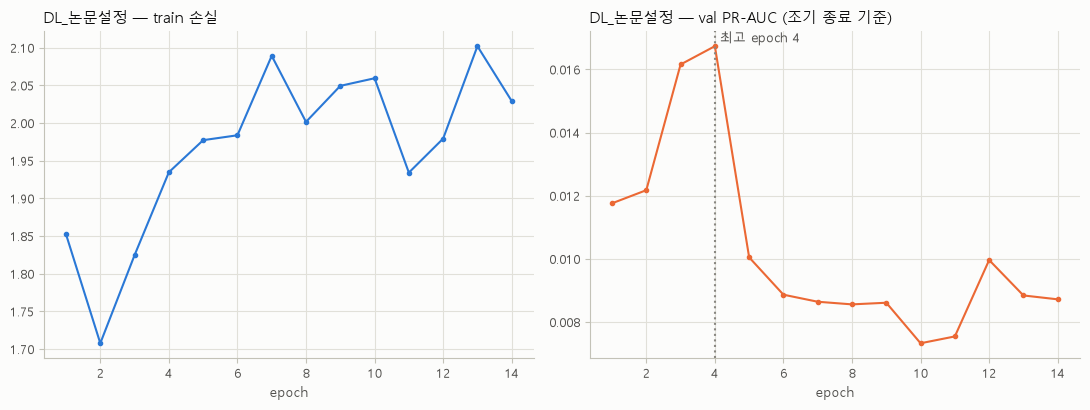

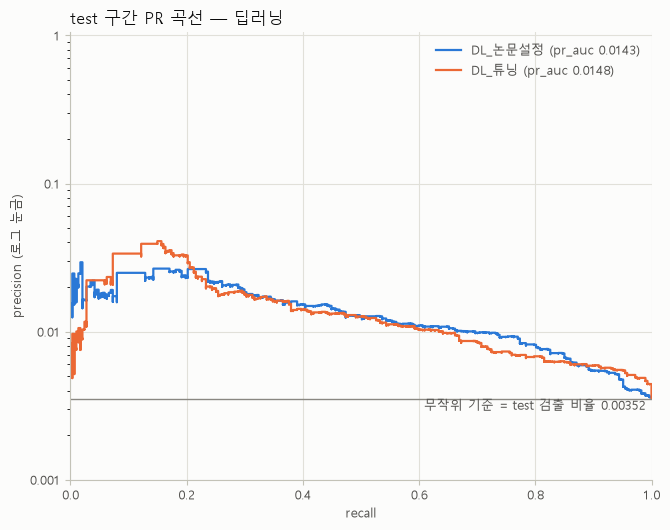

In [8]:
SURFACE, INK, INK2, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
PLAIN = FuncFormatter(lambda v, _: f'{v:g}')
FIGURES = {}
def style_axes(ax):
    ax.set_facecolor(SURFACE); ax.grid(True, color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    for side in ('top', 'right'): ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'): ax.spines[side].set_color(AXIS)
    ax.tick_params(colors=AXIS, labelcolor=INK2, labelsize=9)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), facecolor=SURFACE)
for ax in axes: style_axes(ax)
axes[0].plot(hist_paper['epoch'], hist_paper['train_loss'], color=PALETTE[0], marker='o', markersize=3)
axes[0].set_title('DL_논문설정 — train 손실', loc='left', color=INK, fontsize=11); axes[0].set_xlabel('epoch', color=INK2)
axes[1].plot(hist_paper['epoch'], hist_paper['val_pr_auc'], color=PALETTE[1], marker='o', markersize=3, label='val pr_auc')
axes[1].axvline(ep_paper, color=MUTED, linestyle=':'); axes[1].text(ep_paper, axes[1].get_ylim()[1], f' 최고 epoch {ep_paper}', va='top', color=INK2, fontsize=9)
axes[1].set_title('DL_논문설정 — val PR-AUC (조기 종료 기준)', loc='left', color=INK, fontsize=11); axes[1].set_xlabel('epoch', color=INK2)
fig.tight_layout(); FIGURES['paper_training_curves.png'] = fig; plt.show()

fig, ax = plt.subplots(figsize=(6.8, 5.4), facecolor=SURFACE); style_axes(ax); ax.set_yscale('log', nonpositive='mask')
for color, name in zip(PALETTE, MODELS_DL):
    pr, rc, _ = precision_recall_curve(ys['test'], proba['test'][name])
    ax.plot(rc, pr, drawstyle='steps-post', color=color, linewidth=1.6, label=f'{name} (pr_auc {average_precision_score(ys["test"], proba["test"][name]):.4f})')
pos_rate = ys['test'].mean(); ax.axhline(pos_rate, color=MUTED, linewidth=1)
ax.text(0.99, pos_rate, f'무작위 기준 = test 검출 비율 {pos_rate:.5f}', transform=ax.get_yaxis_transform(), ha='right', va='top', color=INK2, fontsize=9)
ax.set_xlim(0, 1); ax.set_ylim(1e-3, 1.05); ax.yaxis.set_major_formatter(PLAIN)
ax.set_xlabel('recall', color=INK2, fontsize=9); ax.set_ylabel('precision (로그 눈금)', color=INK2, fontsize=9)
ax.set_title('test 구간 PR 곡선 — 딥러닝', loc='left', color=INK, fontsize=12); ax.legend(frameon=False, fontsize=9, labelcolor=INK2)
fig.tight_layout(); FIGURES['test_pr_curve.png'] = fig; plt.show()

## 9. MLflow 에 기록

부모 run `3_딥러닝`(조건·탐색표·학습 곡선·그림·지표·예측 확률·체크포인트 경로) + 자식 run `3_딥러닝 / DL_튜닝 / F2최대` 처럼 모델 2개 × 규칙 3개. 지표 이름은 실험 1·`2_autogluon` 과 같다.

In [9]:
INPUT = f'다운사이징 + 시계열 17변수×100일 + 표 형식(범주형 {len(CAT_COLS)}·수치 {NUM_X.shape[1]})'
NOTEBOOK = r'리스테리아ML\EXP\2\3_딥러닝.ipynb'
STAGE_DESC = '실험 2 — 딥러닝: 논문 Conv1D–BiLSTM–Attention + 표 형식 가지 (논문 설정 / Optuna 튜닝)'
METRIC_KEYS = {c_: c_ for c_ in SCORE_COLS + ['TP', 'FN', 'FP', 'TN']}
METRIC_KEYS.update({'전체 건수': 'n_total', '실제 검출': 'n_pos', '예측 양성 수': 'n_pred_pos'})
BOM = chr(0xFEFF)
parent_params = {
    'input': INPUT, 'data.tabular': str(DATA_DIR / 'tabular.parquet'), 'data.seq': str(DATA_DIR / 'seq_std.npy'),
    'data.meta_made_at': META['made_at'], 'downsizing': META['downsizing']['rule'],
    **{f'split.{r["구간"]}': f'{r["행 수"]:,}행 | 검출 {r["검출(1)"]:,}건' for r in split_summary.to_dict('records')},
    'n_cat': len(CAT_COLS), 'n_num': NUM_X.shape[1], 'seq_vars': N_VARS, 'seq_days': int(SEQ.shape[1]),
    'layer_order': 'Conv/Dense → BatchNorm → ReLU → Dropout', 'attention': 'Bahdanau additive',
    'early_stopping': f'val pr_auc, patience {PATIENCE} (탐색 {HPO_PATIENCE}), 최대 {MAX_EPOCHS} epoch (탐색 {HPO_MAX_EPOCHS})',
    'oversampling': '양성 ×3 (증강 사본 2개, 논문) — 탐색에서는 켬/끔 선택', 'clipnorm': 1.0, 'optimizer': 'Adam',
    'hpo': f'Optuna TPE 최대 {N_TRIALS}회 / {DL_BUDGET_H}h, MedianPruner', 'optuna_storage': OPTUNA_STORAGE, 'ckpt_dir': str(OUT_DIR),
    'device': str(DEVICE), 'seed': SEED, 'threshold_rules': '0.5 / val F1최대 / val F2최대', 'smoke_test': SMOKE_TEST,
}
pred_out = pd.concat([pd.DataFrame({KEY_COL: tab[KEY_COL].to_numpy()[rows[s]], '구간': s, DATE_COL: tab[DATE_COL].to_numpy()[rows[s]],
                                    'y': ys[s].astype(np.int8), **{f'p_{m}': proba[s][m] for m in MODELS_DL}}) for s in ['val', 'test']], ignore_index=True)
if LOG_TO_MLFLOW:
    with mlflow.start_run(run_name=RUN_NAME) as parent:
        mlflow.set_tags({'notebook': NOTEBOOK, 'stage': STAGE_DESC, 'mlflow.note.content': STAGE_DESC})
        mlflow.log_params(parent_params)
        for fname, fig in FIGURES.items(): mlflow.log_figure(fig, f'figures/{fname}')
        mlflow.log_text(BOM + hist_paper.to_csv(index=False), 'history_DL_논문설정.csv')
        mlflow.log_text(BOM + TRIALS.to_csv(index=False), 'optuna_trials.csv')
        mlflow.log_text(BOM + metrics.to_csv(index=False), 'metrics.csv')
        mlflow.log_dict({'paper_cfg': PAPER, 'best_cfg': BEST_CFG, 'best_trial': best.number, 'thresholds': thresholds, 'fit_seconds': FIT_SEC,
                         'best_epoch': {'DL_논문설정': ep_paper, 'DL_튜닝': best.user_attrs['best_epoch']},
                         'versions': {'torch': torch.__version__, 'optuna': optuna.__version__, 'python': sys.version.split()[0]}}, 'config.json')
        with tempfile.TemporaryDirectory() as tmp:
            p = Path(tmp) / 'predictions.parquet'; pred_out.to_parquet(p, index=False); mlflow.log_artifact(str(p))
        for name, (mdl, cfg) in MODELS_DL.items():
            hp = {f'hp.{k}': v for k, v in cfg.items()}
            for rule, t in thresholds[name].items():
                with mlflow.start_run(run_name=f'{RUN_NAME} / {name} / {rule}', nested=True):
                    mlflow.set_tags({'notebook': NOTEBOOK, 'stage': STAGE_DESC, 'model': name, 'threshold_rule': rule})
                    mlflow.log_params({'input': INPUT, 'model': name, 'threshold_rule': rule, 'threshold': t, **hp})
                    values = {'threshold': t, 'fit_seconds': FIT_SEC[name]}
                    for s in ['val', 'test']:
                        row = metrics[(metrics['모델'] == name) & (metrics['구간'] == s) & (metrics['임계값 규칙'] == rule)].iloc[0]
                        values.update({f'{s}_{key}': float(row[col]) for col, key in METRIC_KEYS.items()})
                    mlflow.log_metrics(values)
    print('기록 완료 — 부모 run', RUN_NAME, parent.info.run_id)
else:
    print('LOG_TO_MLFLOW = False — 기록하지 않음')

기록 완료 — 부모 run 3_딥러닝 a73a11c58a5645af93fba7959bae5d17


## 10. 실험 1·AutoGluon 과 비교 (test, F2최대 임계값, pr_auc 순)

In [10]:
def rows_of(exp, prefix=''):
    r = mlflow.search_runs(experiment_names=[exp], filter_string="params.threshold_rule = 'F2최대'")
    if r.empty or 'tags.mlflow.parentRunId' not in r: return pd.DataFrame()
    r = r[r['tags.mlflow.parentRunId'].notna()]
    return pd.DataFrame({'모델': r['tags.mlflow.runName'], 'roc_auc': r['metrics.test_roc_auc'], 'pr_auc': r['metrics.test_pr_auc'],
                         'recall': r['metrics.test_recall'], 'precision': r['metrics.test_precision'], 'TP': r['metrics.test_TP'], '예측 양성 수': r['metrics.test_n_pred_pos']})
cmp = pd.concat([rows_of('리스테리아_EXP1'), rows_of('리스테리아_EXP2')], ignore_index=True)
if not LOG_TO_MLFLOW:
    here = metrics[(metrics['구간'] == 'test') & (metrics['임계값 규칙'] == 'F2최대')][['모델', 'roc_auc', 'pr_auc', 'recall', 'precision', 'TP', '예측 양성 수']]
    cmp = pd.concat([cmp, here.assign(모델='(이번 실행) ' + here['모델'])], ignore_index=True)
display(cmp.sort_values('pr_auc', ascending=False).reset_index(drop=True).round(4).head(30))

,모델,roc_auc,pr_auc,recall,precision,TP,예측 양성 수
0,2_바로학습 / CatBoost / F2최대,0.7975,0.0190,0.2160,0.0284,62.0,2186.0
1,2_바로학습 / LightGBM / F2최대,0.7838,0.0166,0.0348,0.0633,10.0,158.0
2,CatBoost / F2최대,0.7834,0.0165,0.2962,0.0233,85.0,3652.0
3,3_딥러닝 / DL_튜닝 / F2최대,0.7844,0.0148,0.0697,0.0234,20.0,855.0
4,3_딥러닝 / DL_논문설정 / F2최대,0.7878,0.0143,0.2892,0.0199,83.0,4168.0
5,2_autogluon / CatBoost_t029 / F2최대,0.7743,0.0139,0.0871,0.0351,25.0,712.0
6,2_autogluon / LightGBM_t024 / F2최대,0.7568,0.0131,0.0941,0.0317,27.0,852.0
7,2_바로학습 / XGBoost / F2최대,0.7856,0.0130,0.0348,0.0173,10.0,579.0
8,2_autogluon / XGBoost_t027 / F2최대,0.8174,0.0123,0.1289,0.0193,37.0,1915.0
9,2_autogluon / WeightedEnsemble_L2Best / F2최대,0.7794,0.0123,0.2474,0.0174,71.0,4069.0
